In [1]:
import sys
import torch

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)

Python: 3.10.12 (main, Jun 22 2026, 18:55:27) [GCC 11.4.0]
PyTorch: 2.12.0+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 4090
CUDA version: 13.0


In [2]:
%pip install -U "transformers>=4.57.0" datasets accelerate matplotlib pillow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 70.3 MB/s eta 0:00:0000:010:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 389.2/389.2 KB 87.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 97.5 MB/s eta 0:00:00:00:0100:01
  Attempting uninstall: pillow
    Found existing installation: pillow 12.2.0
    Uninstalling pillow-12.2.0:
      Successfully uninstalled pillow-12.2.0
  Attempting uninstall: transformers
    Found existing installation: transformers 5.12.0
    Uninstalling transformers-5.12.0:
      Successfully uninstalled transformers-5.12.0
Note: you may need to restart the kernel to use updated packages.


In [1]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from datasets import load_dataset
from transformers import Sam2Model, Sam2Processor

In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

Device: cuda


In [3]:
#Defining experiment settings 
MODEL_NAME = "facebook/sam2.1-hiera-tiny"

BATCH_SIZE = 1
NUM_EPOCHS = 10
LEARNING_RATE = 1e-4
NUM_WORKERS = 0

CHECKPOINT_DIR = "sam2_vegann_checkpoints"
BEST_MODEL_PATH = os.path.join(
    CHECKPOINT_DIR,
    "best_sam2_vegann_mask_decoder.pt"
)

os.makedirs(CHECKPOINT_DIR, exist_ok=True)

print("Model:", MODEL_NAME)
print("Checkpoint directory:", CHECKPOINT_DIR)

Model: facebook/sam2.1-hiera-tiny
Checkpoint directory: sam2_vegann_checkpoints


In [4]:
#Loading VegAnn
vegann = load_dataset("simonMadec/VegAnn")

print(vegann)
print("Columns:", vegann["train"].column_names)
print("Number of images:", len(vegann["train"]))


DatasetDict({
    train: Dataset({
        features: ['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5'],
        num_rows: 3775
    })
})
Columns: ['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5']
Number of images: 3775


In [5]:
#verify one VegAnn e.g 
sample = vegann["train"][0]

print("Keys:", sample.keys())

for key, value in sample.items():
    print(
        key,
        "| type:",
        type(value),
        "| size/shape:",
        getattr(value, "size", getattr(value, "shape", None))
    )

Keys: dict_keys(['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5'])
image | type: <class 'PIL.PngImagePlugin.PngImageFile'> | size/shape: (512, 512)
mask | type: <class 'PIL.PngImagePlugin.PngImageFile'> | size/shape: (512, 512)
System | type: <class 'str'> | size/shape: None
Orientation | type: <class 'str'> | size/shape: None
latitude | type: <class 'float'> | size/shape: None
longitude | type: <class 'float'> | size/shape: None
date | type: <class 'str'> | size/shape: None
LocAcc | type: <class 'int'> | size/shape: None
Species | type: <class 'str'> | size/shape: None
Owner | type: <class 'str'> | size/shape: None
Dataset-Name | type: <class 'str'> | size/shape: None
TVT-split1 | type: <class 'str'> | size/shape: None
TVT-split2 | type: <class 'str'> | size/shape: None
TVT-split3 | type: <class 'str'> | size/shape: None
TVT-split4 | type: <clas

In [6]:
#Set image and mask coloumn names 

column_names = vegann["train"].column_names

image_candidates = [
    "image",
    "images",
    "rgb",
    "img"
]

mask_candidates = [
    "mask",
    "masks",
    "label",
    "labels",
    "segmentation_mask",
    "annotation"
]

IMAGE_KEY = next(
    (key for key in image_candidates if key in column_names),
    None
)

MASK_KEY = next(
    (key for key in mask_candidates if key in column_names),
    None
)

print("Detected image column:", IMAGE_KEY)
print("Detected mask column:", MASK_KEY)

if IMAGE_KEY is None or MASK_KEY is None:
    raise ValueError(
        f"Could not automatically detect the columns. "
        f"Available columns: {column_names}"
    )

Detected image column: image
Detected mask column: mask


In [7]:
#Creating the val/train split 

split = vegann["train"].train_test_split(
    test_size=0.20,
    seed=42
)

train_hf = split["train"]
val_hf = split["test"]

print("Training images:", len(train_hf))
print("Validation images:", len(val_hf))

Training images: 3020
Validation images: 755


In [ ]:
#Converting masks to binary masks 0 for background and 1 for vegetation 
def prepare_binary_mask(mask):
    """
    Convert a PIL image, NumPy array or tensor into
    a binary uint8 NumPy mask containing only 0 and 1.
    """

    if isinstance(mask, Image.Image):
        mask = np.array(mask)

    elif torch.is_tensor(mask):
        mask = mask.detach().cpu().numpy()

    else:
        mask = np.asarray(mask)

    # If the mask contains multiple channels, keep one channel.
    if mask.ndim == 3:
        mask = mask[..., 0]

    # Any positive value is treated as vegetation.
    mask = (mask > 0).astype(np.uint8)

    return mask

In [9]:
#Generating Bounding box from the mask 
def mask_to_box(mask, box_jitter=0):
    """
    Generate [x_min, y_min, x_max, y_max]
    from a binary vegetation mask.
    """

    y_indices, x_indices = np.where(mask > 0)

    if len(x_indices) == 0 or len(y_indices) == 0:
        return None

    x_min = int(x_indices.min())
    y_min = int(y_indices.min())
    x_max = int(x_indices.max())
    y_max = int(y_indices.max())

    height, width = mask.shape

    if box_jitter > 0:
        x_min -= random.randint(0, box_jitter)
        y_min -= random.randint(0, box_jitter)
        x_max += random.randint(0, box_jitter)
        y_max += random.randint(0, box_jitter)

    x_min = max(0, x_min)
    y_min = max(0, y_min)
    x_max = min(width - 1, x_max)
    y_max = min(height - 1, y_max)

    return [x_min, y_min, x_max, y_max]

In [10]:
#Cgecking for empty boxes -> better to exclude emoty masks as Bounding box cant be 
# created for an image that has no vegetataion e.g. soil only 
def count_empty_masks(hf_dataset):
    empty_count = 0

    for item in hf_dataset:
        mask = prepare_binary_mask(item[MASK_KEY])

        if mask.sum() == 0:
            empty_count += 1

    return empty_count


train_empty = count_empty_masks(train_hf)
val_empty = count_empty_masks(val_hf)

print("Empty training masks:", train_empty)
print("Empty validation masks:", val_empty)



Empty training masks: 54
Empty validation masks: 9


In [11]:
#Create the SAM2 VegAnn dataset class 
""" for every image the class returns 
RGB image, GT binary mask, GT vegetation boc and orignal dataset index"""
class VegAnnSAM2Dataset(Dataset):
    def __init__(
        self,
        hf_dataset,
        image_key,
        mask_key,
        training=False,
        box_jitter=0,
        skip_empty=True
    ):
        self.hf_dataset = hf_dataset
        self.image_key = image_key
        self.mask_key = mask_key
        self.training = training
        self.box_jitter = box_jitter
        self.skip_empty = skip_empty

        self.valid_indices = []

        for index in range(len(hf_dataset)):
            item = hf_dataset[index]
            mask = prepare_binary_mask(item[self.mask_key])

            if self.skip_empty and mask.sum() == 0:
                continue

            self.valid_indices.append(index)

    def __len__(self):
        return len(self.valid_indices)

    def __getitem__(self, index):
        original_index = self.valid_indices[index]
        item = self.hf_dataset[original_index]

        image = item[self.image_key]

        if not isinstance(image, Image.Image):
            image = Image.fromarray(np.asarray(image))

        image = image.convert("RGB")

        mask = prepare_binary_mask(item[self.mask_key])

        box = mask_to_box(
            mask,
            box_jitter=self.box_jitter if self.training else 0
        )

        if box is None:
            height, width = mask.shape
            box = [0, 0, width - 1, height - 1]

        return {
            "image": image,
            "mask": mask,
            "box": box,
            "index": original_index
        }

In [ ]:
#Create Training and Validation datasets 

train_dataset = VegAnnSAM2Dataset(
    hf_dataset=train_hf,
    image_key=IMAGE_KEY,
    mask_key=MASK_KEY,
    training=True,
    box_jitter=10,
    skip_empty=True
)

val_dataset = VegAnnSAM2Dataset(
    hf_dataset=val_hf,
    image_key=IMAGE_KEY,
    mask_key=MASK_KEY,
    training=False,
    box_jitter=0,
    skip_empty=True
)

print("Usable training images:", len(train_dataset))
print("Usable validation images:", len(val_dataset))

Usable training images: 2966
Usable validation images: 746


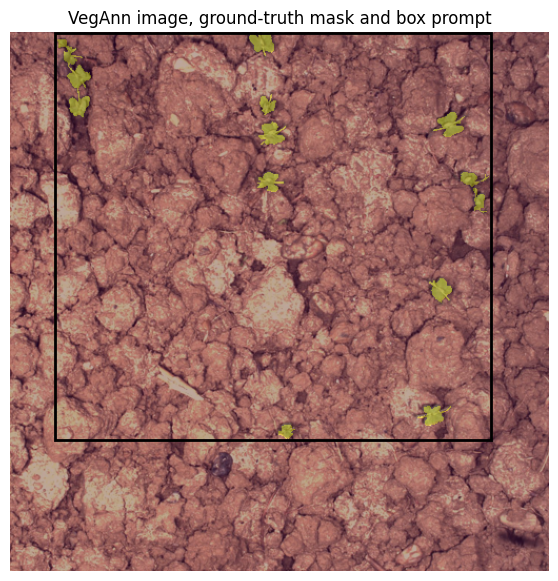

Image shape: (512, 512, 3)
Mask shape: (512, 512)
Box: [42, 0, 456, 387]
Vegetation pixels: 3352


In [14]:
#Visualize
example = train_dataset[0]

image = np.array(example["image"])
mask = example["mask"]
box = example["box"]

x_min, y_min, x_max, y_max = box

plt.figure(figsize=(7, 7))
plt.imshow(image)
plt.imshow(mask, alpha=0.35)

plt.gca().add_patch(
    plt.Rectangle(
        (x_min, y_min),
        x_max - x_min,
        y_max - y_min,
        fill=False,
        linewidth=2
    )
)

plt.title("VegAnn image, ground-truth mask and box prompt")
plt.axis("off")
plt.show()

print("Image shape:", image.shape)
print("Mask shape:", mask.shape)
print("Box:", box)
print("Vegetation pixels:", mask.sum())

In [15]:
#PIL images cannot be stacked directly by the standard DataLoader 
def sam2_collate_fn(batch):
    return {
        "images": [item["image"] for item in batch],
        "masks": [item["mask"] for item in batch],
        "boxes": [item["box"] for item in batch],
        "indices": [item["index"] for item in batch]
    }

In [16]:
#Create Dataloaders 
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    collate_fn=sam2_collate_fn
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    collate_fn=sam2_collate_fn
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 2966
Validation batches: 746


In [17]:
#Loading SAM2.1 and its processor 
processor = Sam2Processor.from_pretrained(MODEL_NAME)

model = Sam2Model.from_pretrained(MODEL_NAME)
model = model.to(device)

print("SAM2 loaded successfully")

processor_config.json:   0%|          | 0.00/95.0 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/683 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/5.70k [00:00<?, ?B/s]

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


model.safetensors:   0%|          | 0.00/156M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

SAM2 loaded successfully


In [18]:
print (model)
print("\nTop-level SAM2 modules:")

for name, module in model.named_children():
    print(name, "->", type(module).__name__)


Sam2Model(
  (shared_image_embedding): Sam2PositionalEmbedding()
  (vision_encoder): Sam2VisionModel(
    (backbone): Sam2HieraDetModel(
      (patch_embed): Sam2PatchEmbeddings(
        (projection): Conv2d(3, 96, kernel_size=(7, 7), stride=(4, 4), padding=(3, 3))
      )
      (blocks): ModuleList(
        (0): Sam2MultiScaleBlock(
          (layer_norm1): LayerNorm((96,), eps=1e-06, elementwise_affine=True, bias=True)
          (attn): Sam2MultiScaleAttention(
            (qkv): Linear(in_features=96, out_features=288, bias=True)
            (proj): Linear(in_features=96, out_features=96, bias=True)
          )
          (layer_norm2): LayerNorm((96,), eps=1e-06, elementwise_affine=True, bias=True)
          (mlp): Sam2FeedForward(
            (activation): GELUActivation()
            (proj_in): Linear(in_features=96, out_features=384, bias=True)
            (proj_out): Linear(in_features=384, out_features=96, bias=True)
            (layers): ModuleList()
          )
        )
    

In [ ]:
#Freezing vision encoder, promot encoder and other SAM2 components except the mask decoder 
for parameter in model.parameters():
    parameter.requires_grad = False


mask_decoder = None

if hasattr(model, "mask_decoder"):
    mask_decoder = model.mask_decoder

elif hasattr(model, "sam_mask_decoder"):
    mask_decoder = model.sam_mask_decoder

else:
    for name, module in model.named_modules():
        if name.endswith("mask_decoder"):
            mask_decoder = module
            print("Detected mask decoder:", name)
            break


if mask_decoder is None:
    raise AttributeError(
        "Could not locate the SAM2 mask decoder. "
        "Please send me the output of Cell 19."
    )


for parameter in mask_decoder.parameters():
    parameter.requires_grad = True


total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print(f"Total parameters: {total_parameters:,}")
print(f"Trainable parameters: {trainable_parameters:,}")
print(
    f"Trainable percentage: "
    f"{100 * trainable_parameters / total_parameters:.4f}%"
)

Total parameters: 31,440,721
Trainable parameters: 4,215,109
Trainable percentage: 13.4065%


In [21]:
#Loss function 
""" BCE for pixel wise classification 
Dice for mask overlap combined gives pixel and region level supervision"""
bce_loss_fn = nn.BCEWithLogitsLoss()


def dice_loss(logits, targets, smooth=1.0):
    probabilities = torch.sigmoid(logits)

    probabilities = probabilities.flatten(1)
    targets = targets.flatten(1)

    intersection = (probabilities * targets).sum(dim=1)

    dice = (
        2.0 * intersection + smooth
    ) / (
        probabilities.sum(dim=1)
        + targets.sum(dim=1)
        + smooth
    )

    return 1.0 - dice.mean()


def combined_segmentation_loss(logits, targets):
    bce = bce_loss_fn(logits, targets)
    dice = dice_loss(logits, targets)

    total = 0.5 * bce + 0.5 * dice

    return total, bce, dice

In [22]:
#Helper for extracting SAM2 mask logits 
def extract_single_mask_logits(pred_masks):
    """
    Convert SAM2 output into [batch, height, width].
    Expected examples:
      [B, 1, 1, H, W]
      [B, 1, H, W]
      [B, H, W]
    """

    logits = pred_masks

    while logits.ndim > 3:
        logits = logits[:, 0]

    return logits


In [23]:
#processor resizes the iamages, transforms box coordinates, converts into Pytorch tensors
def prepare_sam2_batch(batch):
    images = batch["images"]
    masks = batch["masks"]
    boxes = batch["boxes"]

    
    input_boxes = [
        [box]
        for box in boxes
    ]

    inputs = processor(
        images=images,
        segmentation_maps=masks,
        input_boxes=input_boxes,
        return_tensors="pt"
    )

    inputs = {
        key: value.to(device)
        if torch.is_tensor(value)
        else value
        for key, value in inputs.items()
    }

    return inputs

In [27]:
#Tesing one forward pass 
test_batch = next(iter(train_loader))
test_inputs = prepare_sam2_batch(test_batch)

print("Processor output keys:", test_inputs.keys())

for key, value in test_inputs.items():
    if torch.is_tensor(value):
        print(key, value.shape, value.dtype)




Processor output keys: dict_keys(['pixel_values', 'original_sizes', 'labels', 'input_boxes'])
pixel_values torch.Size([1, 3, 1024, 1024]) torch.float32
original_sizes torch.Size([1, 2]) torch.int64
labels torch.Size([1, 256, 256]) torch.int64
input_boxes torch.Size([1, 1, 4]) torch.float32


In [34]:
model.eval()

with torch.no_grad():
    image_embeddings = model.get_image_embeddings(
        test_inputs["pixel_values"]
    )

outputs = model(
    image_embeddings=image_embeddings,
    input_boxes=test_inputs["input_boxes"],
    multimask_output=False
)
print(type(outputs))
print(outputs)
print(outputs.keys())
logits = extract_single_mask_logits(outputs.pred_masks)

targets = test_inputs["labels"].float()

while targets.ndim > 3:
    targets = targets[:, 0]

targets = F.interpolate(
    targets.unsqueeze(1),
    size=logits.shape[-2:],
    mode="nearest"
).squeeze(1)

targets = (targets > 0).float()



print("Raw predicted masks:", outputs.pred_masks.shape)
print("Final logits:", logits.shape)
print("Targets:", targets.shape)

loss, bce, dice = combined_segmentation_loss(
    logits,
    targets
)

print("Test loss:", loss.item())
print("BCE component:", bce.item())
print("Dice component:", dice.item())

<class 'transformers.models.sam2.modeling_sam2.Sam2ImageSegmentationOutput'>
Sam2ImageSegmentationOutput(iou_scores=tensor([[[0.9844]]], device='cuda:0', grad_fn=<WhereBackward0>), pred_masks=tensor([[[[[0.4738, 1.1516, 0.8465,  ..., 1.0337, 1.1851, 0.7610],
           [0.5453, 1.1996, 1.0770,  ..., 1.2810, 1.4921, 1.0236],
           [1.1099, 1.3413, 1.4026,  ..., 1.5622, 1.7049, 1.2120],
           ...,
           [0.9397, 1.3576, 1.3344,  ..., 1.8232, 1.2423, 0.7154],
           [0.8767, 1.5669, 1.3778,  ..., 1.3908, 1.3170, 1.1806],
           [0.4350, 0.8509, 0.7877,  ..., 0.9819, 0.5753, 0.3545]]]]],
       device='cuda:0', grad_fn=<WhereBackward0>), object_score_logits=tensor([[[16.4754]]], device='cuda:0', grad_fn=<ViewBackward0>), image_embeddings=[tensor([[[[ 0.2654,  0.1338,  0.1246,  ...,  0.1721,  0.0689,  0.1465],
          [ 0.2471,  0.0549,  0.0121,  ...,  0.0170,  0.0414,  0.1012],
          [ 0.1216,  0.0089, -0.0589,  ...,  0.0233,  0.0314,  0.0639],
          ...,
 

In [35]:
#Defining the optimizer 
optimizer = torch.optim.AdamW(
    [
        parameter
        for parameter in model.parameters()
        if parameter.requires_grad
    ],
    lr=LEARNING_RATE,
    weight_decay=1e-4
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=torch.cuda.is_available()
)

print("Optimizer created")

Optimizer created


In [36]:
def update_metric_statistics(
    logits,
    targets,
    threshold=0.5,
    epsilon=1e-7
):
    probabilities = torch.sigmoid(logits)
    predictions = (probabilities >= threshold).float()

    predictions = predictions.flatten(1)
    targets = targets.flatten(1)

    intersection = (predictions * targets).sum(dim=1)
    prediction_sum = predictions.sum(dim=1)
    target_sum = targets.sum(dim=1)

    union = prediction_sum + target_sum - intersection

    per_image_iou = (
        intersection + epsilon
    ) / (
        union + epsilon
    )

    per_image_dice = (
        2 * intersection + epsilon
    ) / (
        prediction_sum + target_sum + epsilon
    )

    return {
        "per_image_iou_sum": per_image_iou.sum().item(),
        "per_image_dice_sum": per_image_dice.sum().item(),
        "intersection": intersection.sum().item(),
        "union": union.sum().item(),
        "prediction_sum": prediction_sum.sum().item(),
        "target_sum": target_sum.sum().item(),
        "num_images": targets.shape[0]
    }

In [37]:
loss, bce, dice = combined_segmentation_loss(
    logits,
    targets
)

print(loss)

loss.backward()

print("Backward successful!")

tensor(0.2389, device='cuda:0', grad_fn=<AddBackward0>)
Backward successful!


In [38]:
def train_one_epoch(
    model,
    loader,
    optimizer,
    scaler
):
    model.train()

    running_loss = 0.0
    running_bce = 0.0
    running_dice = 0.0

    for batch_index, batch in enumerate(loader):
        inputs = prepare_sam2_batch(batch)

        optimizer.zero_grad(set_to_none=True)

        # The vision encoder is frozen, so no gradients are stored.
        with torch.no_grad():
            image_embeddings = model.get_image_embeddings(
                inputs["pixel_values"]
            )

        with torch.amp.autocast(
            "cuda",
            enabled=torch.cuda.is_available()
        ):
            outputs = model(
                image_embeddings=image_embeddings,
                input_boxes=inputs["input_boxes"],
                multimask_output=False
            )

            logits = extract_single_mask_logits(
                outputs.pred_masks
            )

            targets = inputs["labels"].float()

            while targets.ndim > 3:
                targets = targets[:, 0]

            targets = F.interpolate(
                targets.unsqueeze(1),
                size=logits.shape[-2:],
                mode="nearest"
            ).squeeze(1)

            targets = (targets > 0).float()

            loss, bce, dice = combined_segmentation_loss(
                logits,
                targets
            )

        scaler.scale(loss).backward()

        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            mask_decoder.parameters(),
            max_norm=1.0
        )

        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()
        running_bce += bce.item()
        running_dice += dice.item()

        if (batch_index + 1) % 100 == 0:
            print(
                f"Batch {batch_index + 1}/{len(loader)} | "
                f"Loss: {running_loss / (batch_index + 1):.4f}"
            )

    number_of_batches = len(loader)

    return {
        "loss": running_loss / number_of_batches,
        "bce": running_bce / number_of_batches,
        "dice_loss": running_dice / number_of_batches
    }

In [39]:
#Defining validation 
@torch.no_grad()
def validate(
    model,
    loader,
    threshold=0.5
):
    model.eval()

    running_loss = 0.0

    metric_totals = {
        "per_image_iou_sum": 0.0,
        "per_image_dice_sum": 0.0,
        "intersection": 0.0,
        "union": 0.0,
        "prediction_sum": 0.0,
        "target_sum": 0.0,
        "num_images": 0
    }

    for batch in loader:
        inputs = prepare_sam2_batch(batch)

        image_embeddings = model.get_image_embeddings(
            inputs["pixel_values"]
        )

        outputs = model(
            image_embeddings=image_embeddings,
            input_boxes=inputs["input_boxes"],
            multimask_output=False
        )

        logits = extract_single_mask_logits(
            outputs.pred_masks
        )

        targets = inputs["labels"].float()

        while targets.ndim > 3:
            targets = targets[:, 0]

        targets = F.interpolate(
            targets.unsqueeze(1),
            size=logits.shape[-2:],
            mode="nearest"
        ).squeeze(1)

        targets = (targets > 0).float()

        loss, _, _ = combined_segmentation_loss(
            logits,
            targets
        )

        running_loss += loss.item()

        batch_metrics = update_metric_statistics(
            logits,
            targets,
            threshold=threshold
        )

        for key in metric_totals:
            metric_totals[key] += batch_metrics[key]

    epsilon = 1e-7

    mean_iou = (
        metric_totals["per_image_iou_sum"]
        / metric_totals["num_images"]
    )

    mean_dice = (
        metric_totals["per_image_dice_sum"]
        / metric_totals["num_images"]
    )

    global_iou = (
        metric_totals["intersection"] + epsilon
    ) / (
        metric_totals["union"] + epsilon
    )

    global_dice = (
        2 * metric_totals["intersection"] + epsilon
    ) / (
        metric_totals["prediction_sum"]
        + metric_totals["target_sum"]
        + epsilon
    )

    return {
        "loss": running_loss / len(loader),
        "mean_iou": mean_iou,
        "mean_dice": mean_dice,
        "global_iou": global_iou,
        "global_dice": global_dice
    }

In [40]:
DEBUG_BATCHES = 5

model.train()

for batch_index, batch in enumerate(train_loader):
    if batch_index >= DEBUG_BATCHES:
        break

    inputs = prepare_sam2_batch(batch)

    optimizer.zero_grad(set_to_none=True)

    with torch.no_grad():
        image_embeddings = model.get_image_embeddings(
            inputs["pixel_values"]
        )

    outputs = model(
        image_embeddings=image_embeddings,
        input_boxes=inputs["input_boxes"],
        multimask_output=False
    )

    logits = extract_single_mask_logits(
        outputs.pred_masks
    )

    targets = inputs["labels"].float()

    while targets.ndim > 3:
        targets = targets[:, 0]

    targets = F.interpolate(
        targets.unsqueeze(1),
        size=logits.shape[-2:],
        mode="nearest"
    ).squeeze(1)

    targets = (targets > 0).float()

    loss, _, _ = combined_segmentation_loss(
        logits,
        targets
    )

    loss.backward()
    optimizer.step()

    print(
        f"Debug batch {batch_index + 1} | "
        f"Loss: {loss.item():.4f}"
    )

Debug batch 1 | Loss: 0.1020
Debug batch 2 | Loss: 0.1530
Debug batch 3 | Loss: 0.2412
Debug batch 4 | Loss: 0.2530
Debug batch 5 | Loss: 1.3152


In [41]:
#Full training loop 
history = {
    "train_loss": [],
    "val_loss": [],
    "mean_iou": [],
    "mean_dice": [],
    "global_iou": [],
    "global_dice": []
}

best_mean_iou = -1.0


for epoch in range(NUM_EPOCHS):
    print(f"\n{'=' * 60}")
    print(f"Epoch {epoch + 1}/{NUM_EPOCHS}")
    print(f"{'=' * 60}")

    train_results = train_one_epoch(
        model=model,
        loader=train_loader,
        optimizer=optimizer,
        scaler=scaler
    )

    val_results = validate(
        model=model,
        loader=val_loader,
        threshold=0.5
    )

    history["train_loss"].append(
        train_results["loss"]
    )

    history["val_loss"].append(
        val_results["loss"]
    )

    history["mean_iou"].append(
        val_results["mean_iou"]
    )

    history["mean_dice"].append(
        val_results["mean_dice"]
    )

    history["global_iou"].append(
        val_results["global_iou"]
    )

    history["global_dice"].append(
        val_results["global_dice"]
    )

    print(
        f"Train Loss: {train_results['loss']:.4f}"
    )

    print(
        f"Validation Loss: {val_results['loss']:.4f}"
    )

    print(
        f"Mean IoU: {100 * val_results['mean_iou']:.2f}%"
    )

    print(
        f"Mean Dice: {100 * val_results['mean_dice']:.2f}%"
    )

    print(
        f"Global IoU: {100 * val_results['global_iou']:.2f}%"
    )

    print(
        f"Global Dice: {100 * val_results['global_dice']:.2f}%"
    )

    if val_results["mean_iou"] > best_mean_iou:
        best_mean_iou = val_results["mean_iou"]

        torch.save(
            {
                "epoch": epoch + 1,
                "model_name": MODEL_NAME,
                "mask_decoder_state_dict":
                    mask_decoder.state_dict(),
                "optimizer_state_dict":
                    optimizer.state_dict(),
                "best_mean_iou":
                    best_mean_iou,
                "history":
                    history
            },
            BEST_MODEL_PATH
        )

        print(
            "Saved new best checkpoint:",
            BEST_MODEL_PATH
        )


Epoch 1/10
Batch 100/2966 | Loss: 0.3063
Batch 200/2966 | Loss: 0.2636
Batch 300/2966 | Loss: 0.2487
Batch 400/2966 | Loss: 0.2336
Batch 500/2966 | Loss: 0.2199
Batch 600/2966 | Loss: 0.2117
Batch 700/2966 | Loss: 0.2040
Batch 800/2966 | Loss: 0.2044
Batch 900/2966 | Loss: 0.2033
Batch 1000/2966 | Loss: 0.2001
Batch 1100/2966 | Loss: 0.1956
Batch 1200/2966 | Loss: 0.1931
Batch 1300/2966 | Loss: 0.1908
Batch 1400/2966 | Loss: 0.1891
Batch 1500/2966 | Loss: 0.1882
Batch 1600/2966 | Loss: 0.1855
Batch 1700/2966 | Loss: 0.1858
Batch 1800/2966 | Loss: 0.1832
Batch 1900/2966 | Loss: 0.1825
Batch 2000/2966 | Loss: 0.1816
Batch 2100/2966 | Loss: 0.1806
Batch 2200/2966 | Loss: 0.1787
Batch 2300/2966 | Loss: 0.1773
Batch 2400/2966 | Loss: 0.1761
Batch 2500/2966 | Loss: 0.1760
Batch 2600/2966 | Loss: 0.1755
Batch 2700/2966 | Loss: 0.1742
Batch 2800/2966 | Loss: 0.1735
Batch 2900/2966 | Loss: 0.1726
Train Loss: 0.1723
Validation Loss: 0.1421
Mean IoU: 85.15%
Mean Dice: 91.34%
Global IoU: 88.91%
G

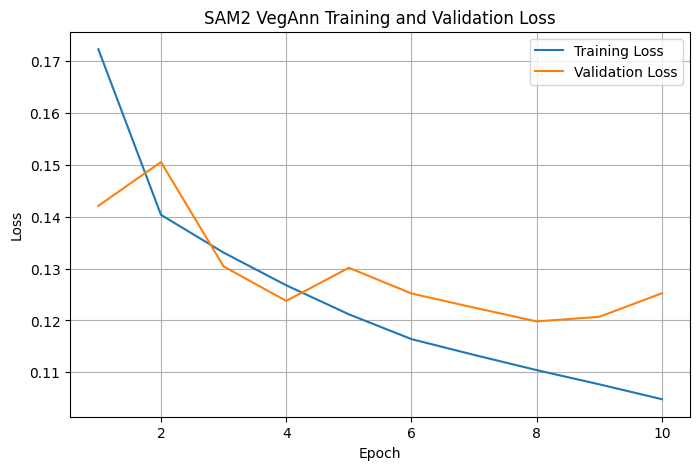

In [42]:
#Plot 
epochs = range(
    1,
    len(history["train_loss"]) + 1
)

plt.figure(figsize=(8, 5))
plt.plot(
    epochs,
    history["train_loss"],
    label="Training Loss"
)
plt.plot(
    epochs,
    history["val_loss"],
    label="Validation Loss"
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("SAM2 VegAnn Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

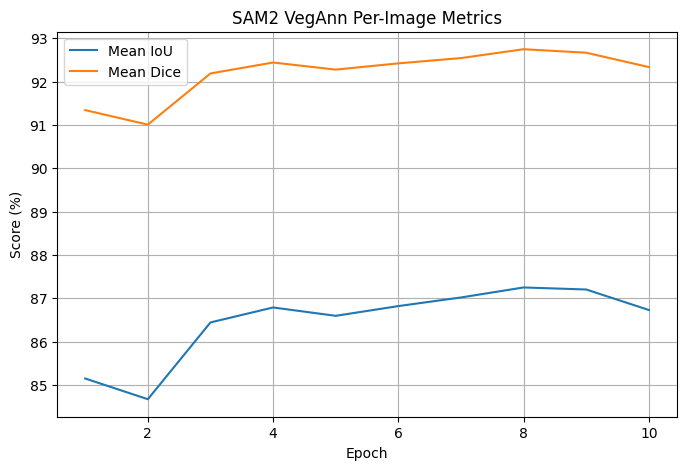

In [43]:
plt.figure(figsize=(8, 5))
plt.plot(
    epochs,
    np.array(history["mean_iou"]) * 100,
    label="Mean IoU"
)
plt.plot(
    epochs,
    np.array(history["mean_dice"]) * 100,
    label="Mean Dice"
)
plt.xlabel("Epoch")
plt.ylabel("Score (%)")
plt.title("SAM2 VegAnn Per-Image Metrics")
plt.legend()
plt.grid(True)
plt.show()

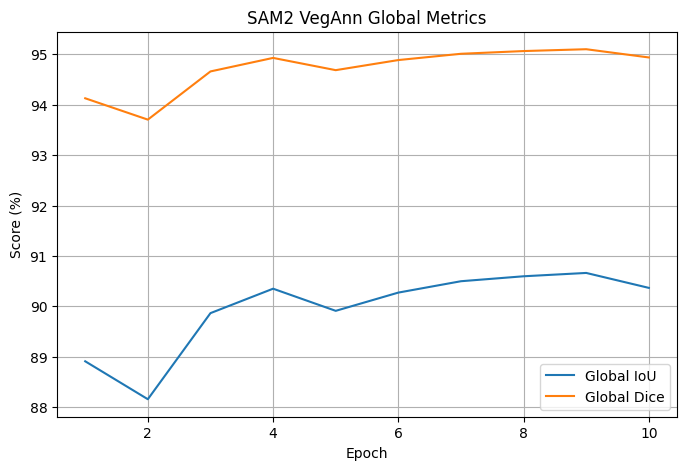

In [44]:
plt.figure(figsize=(8, 5))
plt.plot(
    epochs,
    np.array(history["global_iou"]) * 100,
    label="Global IoU"
)
plt.plot(
    epochs,
    np.array(history["global_dice"]) * 100,
    label="Global Dice"
)
plt.xlabel("Epoch")
plt.ylabel("Score (%)")
plt.title("SAM2 VegAnn Global Metrics")
plt.legend()
plt.grid(True)
plt.show()

In [45]:
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=False
)

mask_decoder.load_state_dict(
    checkpoint["mask_decoder_state_dict"]
)

print("Loaded checkpoint from epoch:", checkpoint["epoch"])
print(
    "Best Mean IoU:",
    f"{100 * checkpoint['best_mean_iou']:.2f}%"
)

Loaded checkpoint from epoch: 8
Best Mean IoU: 87.25%


In [46]:
final_results = validate(
    model=model,
    loader=val_loader,
    threshold=0.5
)

print("Final best-model results")
print("------------------------")
print(f"Validation Loss: {final_results['loss']:.4f}")
print(f"Mean IoU:       {100 * final_results['mean_iou']:.2f}%")
print(f"Mean Dice:      {100 * final_results['mean_dice']:.2f}%")
print(f"Global IoU:     {100 * final_results['global_iou']:.2f}%")
print(f"Global Dice:    {100 * final_results['global_dice']:.2f}%")

Final best-model results
------------------------
Validation Loss: 0.1198
Mean IoU:       87.25%
Mean Dice:      92.75%
Global IoU:     90.60%
Global Dice:    95.07%


In [47]:
#Predictr one val image (running fine tuned SAM2 on one validation image)
@torch.no_grad()
def predict_validation_sample(model, dataset, sample_index):
    model.eval()

    item = dataset[sample_index]

    batch = sam2_collate_fn([item])
    inputs = prepare_sam2_batch(batch)

    image_embeddings = model.get_image_embeddings(
        inputs["pixel_values"]
    )

    outputs = model(
        image_embeddings=image_embeddings,
        input_boxes=inputs["input_boxes"],
        multimask_output=False
    )

    logits = extract_single_mask_logits(
        outputs.pred_masks
    )

    probabilities = torch.sigmoid(logits)

    prediction = (probabilities >= 0.5).float()

    original_height, original_width = item["mask"].shape

    prediction = F.interpolate(
        prediction.unsqueeze(1),
        size=(original_height, original_width),
        mode="bilinear",
        align_corners=False
    ).squeeze(1)

    prediction = (
        prediction[0].cpu().numpy() >= 0.5
    ).astype(np.uint8)

    return {
        "image": np.array(item["image"]),
        "ground_truth": item["mask"],
        "prediction": prediction,
        "box": item["box"]
    }

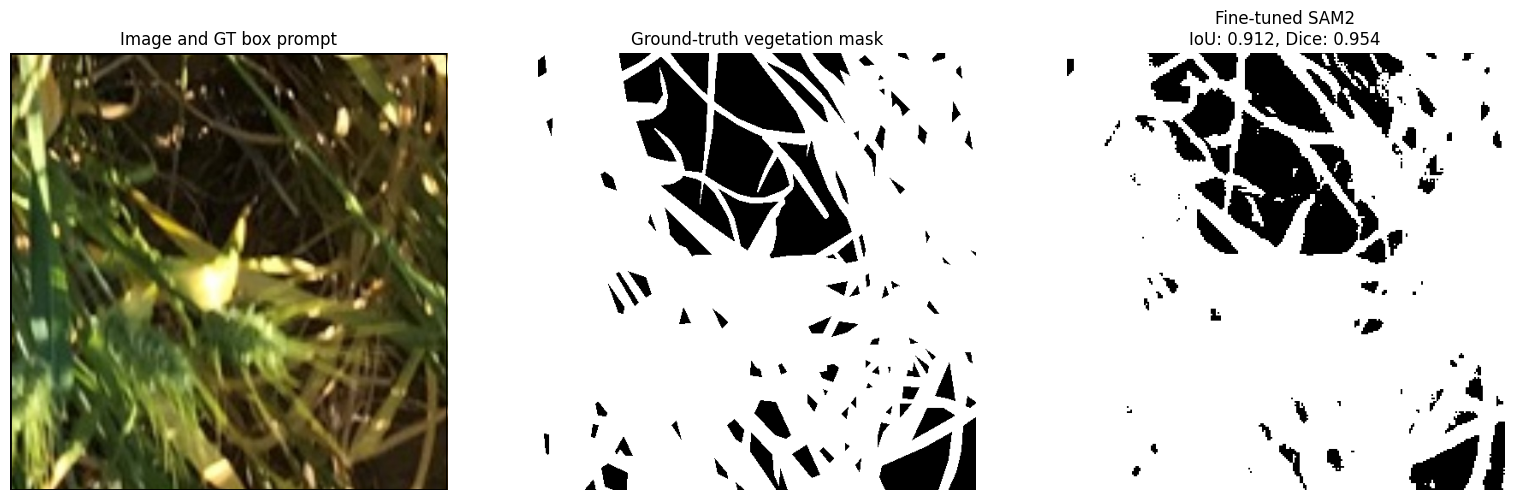

In [48]:
#Visualize prediction 
result = predict_validation_sample(
    model,
    val_dataset,
    sample_index=0
)

image = result["image"]
ground_truth = result["ground_truth"]
prediction = result["prediction"]
box = result["box"]

intersection = np.logical_and(
    prediction,
    ground_truth
).sum()

union = np.logical_or(
    prediction,
    ground_truth
).sum()

sample_iou = intersection / (union + 1e-7)

sample_dice = (
    2 * intersection
    / (
        prediction.sum()
        + ground_truth.sum()
        + 1e-7
    )
)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 5)
)

axes[0].imshow(image)

x_min, y_min, x_max, y_max = box

axes[0].add_patch(
    plt.Rectangle(
        (x_min, y_min),
        x_max - x_min,
        y_max - y_min,
        fill=False,
        linewidth=2
    )
)

axes[0].set_title("Image and GT box prompt")
axes[0].axis("off")

axes[1].imshow(ground_truth, cmap="gray")
axes[1].set_title("Ground-truth vegetation mask")
axes[1].axis("off")

axes[2].imshow(prediction, cmap="gray")
axes[2].set_title(
    f"Fine-tuned SAM2\n"
    f"IoU: {sample_iou:.3f}, "
    f"Dice: {sample_dice:.3f}"
)
axes[2].axis("off")

plt.tight_layout()
plt.show()